# بخش 5: محوشدگی و انفجار گرادیان (موضوع اصلی)

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import time
import matplotlib.pyplot as plt

from data_utils import get_dataloaders
from plotting import save_figure, save_table


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
data_path = None
batch_size = 64
hidden_size = 32
epochs = 50
learning_rate = 0.01



5-1 آزمایش 1: RNN عمیق

یک RNN با 5 لایه بازگشتی (اندازه نهان هر لایه 32) طراحی کنید. در حین آموزش، نُرم گرادیان را برای اولین لایه بازگشتی و آخرین لایه بازگشتی (نسبت به ورودی لایه) ذخیره کنید. نموداری شامل دو منحنی (نرم گرادیان لایه اول و لایه پنجم) بر حسب شماره دوره رسم کنید.


In [3]:
# CELL 2: Define RNN model with gradient tracking

class DeepRNN(nn.Module):
    def __init__(self, input_size=5, hidden_size=32, num_layers=5, output_size=1):
        super(DeepRNN, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True, nonlinearity='tanh')
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.rnn(x, h0)
        out = out[:, -1, :]
        return self.fc(out).squeeze(-1)

def get_gradient_norms(model):
    """Return gradient L2 norms of first and last RNN layers."""
    grad_first = 0.0
    grad_last = 0.0
    # The RNN parameters are in model.rnn.weight_ih_l0, weight_hh_l0, etc.
    for name, param in model.named_parameters():
        if 'rnn' in name and param.grad is not None:
            if 'weight_ih_l0' in name or 'weight_hh_l0' in name:
                grad_first = param.grad.norm(2).item()
            if 'weight_ih_l4' in name or 'weight_hh_l4' in name:  # last layer index 4 (0-based)
                grad_last = param.grad.norm(2).item()
    return grad_first, grad_last

In [5]:
train_loader, test_loader, _ = get_dataloaders(seq_length=20, batch_size=batch_size, data_path=data_path)

model = DeepRNN(input_size=5, hidden_size=hidden_size, num_layers=5, output_size=1)
model.to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)


In [6]:

grad_first_history = []
grad_last_history = []
train_losses = []
test_losses = []

for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        
        # Record gradient norms after backward
        gf, gl = get_gradient_norms(model)
        grad_first_history.append(gf)
        grad_last_history.append(gl)
        
        optimizer.step()
        epoch_loss += loss.item()
    
    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    # Evaluation
    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            test_loss += loss.item()
    avg_test_loss = test_loss / len(test_loader)
    test_losses.append(avg_test_loss)
    
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1:2d}/{epochs} | Train Loss: {avg_train_loss:.6f} | Test Loss: {avg_test_loss:.6f} | Grad First: {gf:.2e} | Grad Last: {gl:.2e}")


Epoch 10/50 | Train Loss: 1.009597 | Test Loss: 1.176994 | Grad First: 1.26e-06 | Grad Last: 2.64e-03
Epoch 20/50 | Train Loss: 0.751182 | Test Loss: 0.880958 | Grad First: 5.90e-07 | Grad Last: 2.43e-04
Epoch 30/50 | Train Loss: 0.754238 | Test Loss: 0.868887 | Grad First: 6.60e-08 | Grad Last: 3.24e-04
Epoch 40/50 | Train Loss: 0.745596 | Test Loss: 0.857458 | Grad First: 1.82e-11 | Grad Last: 3.69e-05
Epoch 50/50 | Train Loss: 0.756512 | Test Loss: 0.879377 | Grad First: 1.37e-11 | Grad Last: 2.84e-06


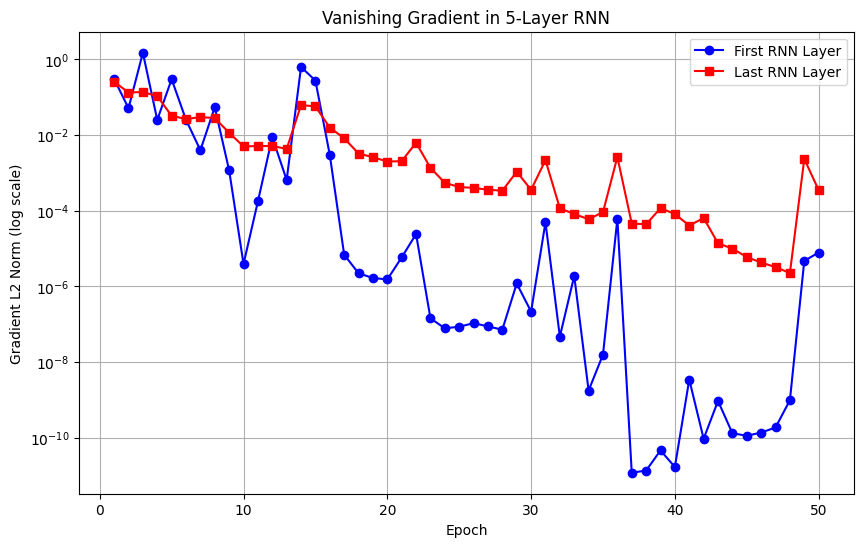

In [7]:

# Plot gradient norms
fig, ax = plt.subplots(figsize=(10, 6))
epochs_range = range(1, epochs+1)
# Average gradient per epoch (since we recorded per batch, take average per epoch)
grad_first_avg = [np.mean(grad_first_history[i*len(train_loader):(i+1)*len(train_loader)]) for i in range(epochs)]
grad_last_avg = [np.mean(grad_last_history[i*len(train_loader):(i+1)*len(train_loader)]) for i in range(epochs)]
ax.semilogy(epochs_range, grad_first_avg, 'b-o', label='First RNN Layer')
ax.semilogy(epochs_range, grad_last_avg, 'r-s', label='Last RNN Layer')
ax.set_xlabel('Epoch')
ax.set_ylabel('Gradient L2 Norm (log scale)')
ax.set_title('Vanishing Gradient in 5-Layer RNN')
ax.legend()
ax.grid(True)
plt.show()
save_figure(fig, "gradient_vanishing_deep_rnn")


الف) آیا شاهدی از محوشدگی گرادیان (vanishing gradient) مشاهده می‌کنید؟ توضیح دهید.

ب) در صورت وجود محوشدگی، راهکارهای پیشنهادی شما چیست؟

5-2 آزمایش 2: دنباله‌های بسیار بلند

طول پنجره ورودی را مقادیر 50, 100, 250, 500 قرار دهید(با RNN ساده و LSTM روی مجموعه داده اصلی). مقدار نهایی MSE روی مجموعه آزمون را ثبت کنید. آیا برای طول‌ های بسیار بلند،LSTM  برتری قابل توجهی نشان می‌دهد؟ تحلیل کنید که کدام سازوکار در LSTM به این برتری کمک می‌کند.

In [9]:
class SimpleLSTM(nn.Module):
	def __init__(self, input_size=5, hidden_size=32, output_size=1):
		super().__init__()
		self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
		self.fc = nn.Linear(hidden_size, output_size)
	def forward(self, x):
		out, _ = self.lstm(x)
		out = out[:, -1, :]
		return self.fc(out).squeeze(-1)


In [10]:
seq_lengths_long = [50, 100, 250, 500]
results_long = []

for seq_len in seq_lengths_long:
    print(f"\n--- Sequence Length = {seq_len} ---")
    train_loader, test_loader, _ = get_dataloaders(seq_length=seq_len, batch_size=batch_size, data_path=data_path)
    
    # RNN
    model_rnn = DeepRNN(input_size=5, hidden_size=hidden_size, num_layers=1, output_size=1)
    model_rnn.to(device)
    optimizer_rnn = optim.Adam(model_rnn.parameters(), lr=learning_rate)
    # Train for fewer epochs to save time
    print("RNN")
    for epoch in range(30):
        model_rnn.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer_rnn.zero_grad()
            loss = nn.MSELoss()(model_rnn(X_batch), y_batch)
            loss.backward()
            optimizer_rnn.step()
        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1:2d}")
    model_rnn.eval()
    with torch.no_grad():
        test_loss = 0.0
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model_rnn(X_batch)
            test_loss += nn.MSELoss()(outputs, y_batch).item()
    mse_rnn = test_loss / len(test_loader)
    
    # LSTM

    model_lstm = SimpleLSTM(input_size=5, hidden_size=hidden_size, output_size=1)
    model_lstm.to(device)
    optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=learning_rate)
    print("LSTM")
    for epoch in range(30):
        model_lstm.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer_lstm.zero_grad()
            loss = nn.MSELoss()(model_lstm(X_batch), y_batch)
            loss.backward()
            optimizer_lstm.step()
        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1:2d}")
    model_lstm.eval()
    with torch.no_grad():
        test_loss = 0.0
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model_lstm(X_batch)
            test_loss += nn.MSELoss()(outputs, y_batch).item()
    mse_lstm = test_loss / len(test_loader)
    
    results_long.append({'Seq Length': seq_len, 'RNN MSE': mse_rnn, 'LSTM MSE': mse_lstm})
    print(f"RNN MSE: {mse_rnn:.6f}, LSTM MSE: {mse_lstm:.6f}")



--- Sequence Length = 50 ---
RNN
Epoch 10
Epoch 20
Epoch 30
LSTM
Epoch 10
Epoch 20
Epoch 30
RNN MSE: 0.403041, LSTM MSE: 0.394493

--- Sequence Length = 100 ---
RNN
Epoch 10
Epoch 20
Epoch 30
LSTM
Epoch 10
Epoch 20
Epoch 30
RNN MSE: 0.413739, LSTM MSE: 0.394586

--- Sequence Length = 250 ---
RNN
Epoch 10
Epoch 20
Epoch 30
LSTM
Epoch 10
Epoch 20
Epoch 30
RNN MSE: 0.401602, LSTM MSE: 0.394256

--- Sequence Length = 500 ---
RNN
Epoch 10
Epoch 20
Epoch 30
LSTM
Epoch 10
Epoch 20
Epoch 30
RNN MSE: 0.411540, LSTM MSE: 0.393442



 Seq Length  RNN MSE  LSTM MSE
         50 0.403041  0.394493
        100 0.413739  0.394586
        250 0.401602  0.394256
        500 0.411540  0.393442


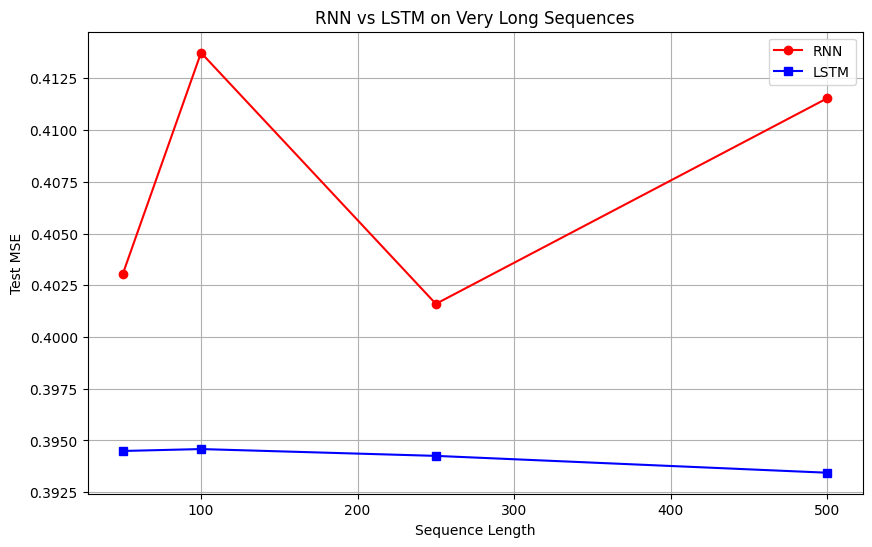

In [11]:

df_long = pd.DataFrame(results_long)
print("\n" + "="*70)
print(df_long.to_string(index=False))
save_table(df_long, 'rnn_vs_lstm_long_seq')

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(df_long['Seq Length'], df_long['RNN MSE'], 'ro-', label='RNN')
ax.plot(df_long['Seq Length'], df_long['LSTM MSE'], 'bs-', label='LSTM')
ax.set_xlabel('Sequence Length')
ax.set_ylabel('Test MSE')
ax.set_title('RNN vs LSTM on Very Long Sequences')
ax.legend()
ax.grid(True)
plt.show()
save_figure(fig, 'rnn_lstm_long_seq')

5-3 آزمایش 3: برش گرادیان (Gradient Clipping)

در معماری RNN با 5 لایه و طول پنجره 200، از تابع clip_grad_norm با آستانه‌های 0.5, 1.0, 2.0, 5.0 استفاده کنید. 

الف) تأثیر برش گرادیان را بر روی همگرایی و پایداری آموزش نشان دهید.

ب) آیا برای مجموعه داده ما عمدتاً مشکل محوشدگی داریم یا انفجار گرادیان؟ چگونه می توان از روی نُرم گرادیان قضاوت کرد؟

In [12]:
seq_len_clip = 200
train_loader, test_loader, _ = get_dataloaders(seq_length=seq_len_clip, batch_size=batch_size, data_path=data_path)


In [13]:

clip_values = [0.5, 1.0, 2.0, 5.0]
clip_results = []

for clip_val in clip_values:
    print(f"\n--- Gradient Clipping Threshold = {clip_val} ---")
    model = DeepRNN(input_size=5, hidden_size=hidden_size, num_layers=5, output_size=1)
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.MSELoss()
    
    train_losses = []
    test_losses = []
    grad_norms = []
    
    for epoch in range(50):
        model.train()
        epoch_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            # Apply gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip_val)
            optimizer.step()
            epoch_loss += loss.item()
        train_losses.append(epoch_loss / len(train_loader))
        
        # Evaluation
        model.eval()
        test_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in test_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                test_loss += criterion(outputs, y_batch).item()
        test_losses.append(test_loss / len(test_loader))
        
        # Record gradient norm after clipping (optional)
        total_norm = 0.0
        for p in model.parameters():
            if p.grad is not None:
                total_norm += p.grad.norm(2).item() ** 2
        total_norm = total_norm ** 0.5
        grad_norms.append(total_norm)
        
        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1:2d}/50 | Train Loss: {train_losses[-1]:.6f} | Test Loss: {test_losses[-1]:.6f} | Grad Norm: {total_norm:.2e}")
    
    clip_results.append({
        'clip_value': clip_val,
        'final_train_loss': train_losses[-1],
        'final_test_loss': test_losses[-1],
        'final_grad_norm': grad_norms[-1]
    })



--- Gradient Clipping Threshold = 0.5 ---
Epoch 10/50 | Train Loss: 1.013514 | Test Loss: 1.185204 | Grad Norm: 3.70e-01
Epoch 20/50 | Train Loss: 1.006214 | Test Loss: 1.176560 | Grad Norm: 5.00e-01
Epoch 30/50 | Train Loss: 1.002714 | Test Loss: 1.179459 | Grad Norm: 5.00e-01
Epoch 40/50 | Train Loss: 1.007577 | Test Loss: 1.168489 | Grad Norm: 5.00e-01
Epoch 50/50 | Train Loss: 1.005200 | Test Loss: 1.208089 | Grad Norm: 5.00e-01

--- Gradient Clipping Threshold = 1.0 ---
Epoch 10/50 | Train Loss: 0.466619 | Test Loss: 0.474680 | Grad Norm: 1.00e+00
Epoch 20/50 | Train Loss: 0.481105 | Test Loss: 0.484955 | Grad Norm: 1.00e+00
Epoch 30/50 | Train Loss: 0.480916 | Test Loss: 0.485694 | Grad Norm: 8.36e-01
Epoch 40/50 | Train Loss: 0.515484 | Test Loss: 0.562466 | Grad Norm: 1.00e+00
Epoch 50/50 | Train Loss: 0.491696 | Test Loss: 0.494602 | Grad Norm: 7.09e-01

--- Gradient Clipping Threshold = 2.0 ---
Epoch 10/50 | Train Loss: 0.611070 | Test Loss: 0.510375 | Grad Norm: 7.86e-01
Ep

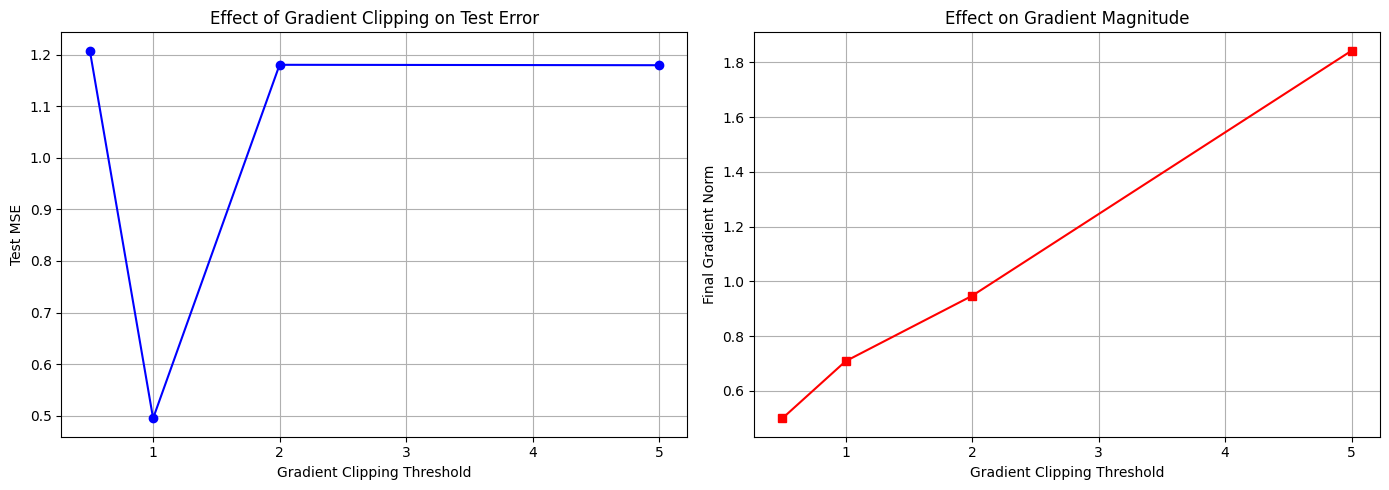


 clip_value  final_train_loss  final_test_loss  final_grad_norm
        0.5          1.005200         1.208089         0.500000
        1.0          0.491696         0.494602         0.708628
        2.0          1.009629         1.180752         0.947395
        5.0          1.013762         1.179951         1.842340


,clip_value,final_train_loss,final_test_loss,final_grad_norm
0,0.5,1.005200,1.208089,0.500000
1,1.0,0.491696,0.494602,0.708628
2,2.0,1.009629,1.180752,0.947395
3,5.0,1.013762,1.179951,1.842340


In [16]:

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
clip_vals_plot = [r['clip_value'] for r in clip_results]
test_losses_plot = [r['final_test_loss'] for r in clip_results]
axes[0].plot(clip_vals_plot, test_losses_plot, 'bo-')
axes[0].set_xlabel('Gradient Clipping Threshold')
axes[0].set_ylabel('Test MSE')
axes[0].set_title('Effect of Gradient Clipping on Test Error')
axes[0].grid(True)

grad_norms_plot = [r['final_grad_norm'] for r in clip_results]
axes[1].plot(clip_vals_plot, grad_norms_plot, 'rs-')
axes[1].set_xlabel('Gradient Clipping Threshold')
axes[1].set_ylabel('Final Gradient Norm')
axes[1].set_title('Effect on Gradient Magnitude')
axes[1].grid(True)
plt.tight_layout()
plt.show()
save_figure(fig, 'gradient_clipping_effect')

df_clip = pd.DataFrame(clip_results)
print("\n" + "="*70)
print(df_clip.to_string(index=False))
save_table(df_clip, 'gradient_clipping_results')